# Метапространство: формальная реконструкция и программа проверки

### Когерентность, энтропия и эффективная размерность в комплексных динамических системах

**Версия 8.0 — научная редакция.** Исходная формулировка: А. Панин, манифест v7.2 «Срединный путь и Грань гармонии». Научная редакция, численные эксперименты и редакция текста: LLM-коллаборация. Дата: 25 октября 2026 г.

---

**Аннотация.** Документ переводит манифест v7.2 в форму, допускающую проверку: явно определяет объекты, отделяет определения от утверждений, формулирует гипотезы с нулевыми моделями и приводит результаты численных экспериментов. Три основных результата. (1) Наблюдаемые $K$, $S_R$ и $C$ сводятся к известным величинам — параметру порядка Курамото, шенноновской энтропии и квадратурной дисперсии; в узкополосном режиме $K$ и $C$ функционально зависимы, поэтому «плоскость $(E,C)$» не является независимым пространством состояний. (2) Динамическая система $(E,C)$ из v7.2 не имеет предельного цикла: дивергенция поля строго отрицательна (критерий Дюлака), а нетривиальное равновесие всегда является устойчивым узлом с вещественными отрицательными собственными значениями; дискриминант характеристического многочлена положителен при всех допустимых параметрах. (3) Критерий «шум vs гениальность» заменяется калиброванным статистическим решением: наивный порог по выборочному выигрышу даёт FDR $\approx 0.81$, тогда как процедура Бенджамини—Хохберга удерживает FDR $\approx 0.10$ при том же качестве ранжирования. Обсуждаются необходимые условия предельного цикла, программа измерений и границы применимости.

**Ключевые слова:** когерентность, параметр порядка, энтропия, эффективная размерность, предельный цикл, критерий Дюлака, множественные сравнения, FDR.


## 0. Статус документа и правила чтения

Этот документ — **не физическая теория и не манифест**. Это математическая реконструкция: множество определений, несколько утверждений с доказательствами, набор проверяемых гипотез и отчёт о численных экспериментах. Всё, что не удаётся свести к этим категориям, из текста удалено; полный аудит исходных аксиом приведён в `docs/audit.md`.

Правила, по которым построен текст:

1. **Каждый объект определён до использования.** Если у операции нет определения, она не считается операцией.
2. **Каждое утверждение имеет истинностное значение и способ проверки.** «Аксиома» — это не способ защитить утверждение от проверки.
3. **Каждое число имеет единицы, погрешность и источник.** Числа без вывода и без неопределённости не используются как параметры модели.
4. **Никаких эпонимов без ссылки.** Название не заменяет доказательство.
5. **Метафора допустима только как комментарий**, но не как аргумент.

| Было в v7.2 | Стало в v8 |
|---|---|
| 22 аксиомы, включая эзотерические | 4 определения, 3 предложения, 5 гипотез; остальное удалено или понижено в статусе |
| «Предельный цикл» как данность | Теорема об отсутствии цикла + необходимые условия его существования |
| «Грань гармонии» $\chi$ как решающее правило | Калиброванный статистический тест с контролем FDR |
| «Срединный путь» как аттрактор | Функционал баланса + задача управления |
| «Квант мерности» $\lambda$, шесть сфер, $\alpha_{\text{life}}=\pi$ | Удалено: нет вывода, единиц и механизма |


In [1]:
import sys
import pathlib

ROOT = pathlib.Path.cwd()
while not (ROOT / "metaspace").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from metaspace import Flow
from metaspace import experiments as ex
from metaspace.plotting import setup_style
from metaspace import (
    coherence,
    born_entropy,
    quadrature_capacity,
    participation_dimension,
    balance_functional,
    shannon_entropy,
)
from metaspace.dynamics import semi_implicit_trajectory

setup_style()
plt.rcParams["figure.max_open_warning"] = 0

print("Python:      ", sys.version.split()[0])
print("NumPy:       ", np.__version__)
print("Matplotlib:  ", matplotlib.__version__)
print("Корень:      ", ROOT)


Python:       3.13.1
NumPy:        2.3.4
Matplotlib:   3.10.8
Корень:       C:\Users\afina\OneDrive\Dokumenty\deepseek-harness\default-workspace


## 1. Формальное ядро

### 1.1. Состояние и наблюдаемые

**Определение 1.1 (состояние).** Состояние — пара $X=(\psi,\alpha)$, где $\psi\in\mathbb{C}^N$ — комплексный вектор, а $\alpha=a+ib\in\mathbb{C}$ — параметр среза. Вещественная часть $a\ge 0$ интерпретируется как **эффективная размерность** (измеримая величина), мнимая часть $b$ — как **параметр аналитического продолжения**. Величина $b$ не является размерностью в топологическом смысле: у неё нет ни метрики, ни меры, ни определения размерности, которое позволяло бы её измерить независимо. Слово «метапространство» ниже обозначает множество таких состояний, а не новое физическое пространство.

**Определение 1.2 (когерентность, энтропия, ёмкость).** Для $\psi\ne 0$:

$$
K(X)=\frac{\left|\sum_{i=1}^{N}\psi_i\right|}{\sum_{i=1}^{N}|\psi_i|}\in[0,1],
\qquad
p_i=\frac{|\psi_i|^2}{\sum_{j=1}^{N}|\psi_j|^2},
\qquad
S_R(X)=-\sum_{i=1}^{N}p_i\ln p_i\ge 0,
$$

$$
\bar\varphi=\arg\sum_{i=1}^{N}\psi_i,
\qquad
C(X)=\frac{\sum_{i=1}^{N}\left|\operatorname{Im}\left(e^{-i\bar\varphi}\psi_i\right)\right|^2}{\sum_{i=1}^{N}|\psi_i|^2}\in[0,1].
$$

$K$ — взвешенный параметр порядка Курамото (при равных амплитудах — стандартный); $S_R$ — шенноновская энтропия распределения Борна; $C$ — нормированная дисперсия квадратуры, ортогональной средней фазе.

**Отличие от v7.2.** В манифесте было $C=\sum_i\|\operatorname{Im}\psi_i\|^2$. Эта величина не инвариантна относительно глобального поворота фазы $\psi\mapsto e^{i\theta}\psi$: её значение зависит от произвольного выбора начала отсчёта фаз. В v8 начало отсчёта привязано к средней фазе $\bar\varphi$, поэтому $C$ инвариантна относительно глобального $U(1)$ и имеет смысл только вместе с указанием этого соглашения.

**Определение 1.3 (эффективная размерность).** Для неотрицательного спектра $\lambda_i$ (собственные числа оператора состояния, сингулярные числа, веса мод) определим

$$
D_{\mathrm{eff}}=\frac{\left(\sum_i\lambda_i\right)^2}{\sum_i\lambda_i^2}\in[1,N].
$$

Для равномерного спектра из $N$ мод $D_{\mathrm{eff}}=N$; для одной моды $D_{\mathrm{eff}}=1$. Это операциональная замена вещественной части «комплексной размерности»: величина $D_{\mathrm{eff}}$ оценивается по данным и имеет доверительный интервал.

**Операциональный статус $a$ и $b$.** В конкретной модели $a$ должно быть отождествлено с выбранной оценкой размерности (например, $D_{\mathrm{eff}}$); без такого отождествления $a$ — свободный параметр, а не наблюдаемая. Аналогично, утверждения, зависящие от $b$, проверяемы только после задания конкретного аналитического продолжения; в v8 такие утверждения не используются, кроме формального определения функционалов баланса. Это ограничение важно: «комплексная размерность» сама по себе не является измеримой величиной.

**Определение 1.4 (функционалы баланса).** Для $N\ge 2$, $a_{\mathrm{ref}}\ge 0$ (опорная размерность, задаваемая задачей) и $S_{\max}=\ln N$:

$$
\mu(X)=\frac{1}{5}\left[(1-K)+\frac{S_R}{S_{\max}}+C+\frac{|b|}{1+|b|}+\frac{|a-a_{\mathrm{ref}}|}{1+|a-a_{\mathrm{ref}}|}\right],
$$

$$
\nu(X)=\frac{1}{5}\left[K+\left(1-\frac{S_R}{S_{\max}}\right)+e^{-C}+\frac{1}{1+b^2}+\frac{1}{1+|a-a_{\mathrm{ref}}|}\right].
$$

Оба функционала лежат в $[0,1]$; $\mu$ измеряет некогерентность и перемешивание, $\nu$ — порядок и «абсолютность». Множество баланса — поверхность $\{\mu=\nu\}$ коразмерности один. В отличие от v7.2, здесь нет привилегированной размерности $\pi$: $a_{\mathrm{ref}}$ задаётся конкретной задачей, а не выбирается из нумерологии. Эмпирическое содержание (1.4) зависит от того, как заданы $a$ и $b$; в эксперименте §4 используется редуцированная версия без $a,b$.


In [2]:
rng = np.random.default_rng(7)

# Один «типичный» вектор: разные амплитуды и разброс фаз.
amplitudes = rng.gamma(shape=2.0, scale=0.6, size=12)
psi = amplitudes * np.exp(1j * rng.normal(0.0, 0.35, 12))
K = coherence(psi)
S = born_entropy(psi)
C = quadrature_capacity(psi)
D = participation_dimension(np.abs(psi) ** 2)

print(f"K  = {K:.4f}   (0 — полная декогеренция, 1 — синхронизация)")
print(f"S  = {S:.4f} нат   (максимум ln 12 = {np.log(12):.4f})")
print(f"C  = {C:.4f}   (0 — фазы лежат на одной оси)")
print(f"2(1-K) = {2 * (1 - K):.4f}")
print(f"D_eff  = {D:.3f}")

aligned = np.array([1.0, 2.0, 3.0])
anti = np.array([1.0, -1.0])
print(f"\nK(выровненный)  = {coherence(aligned):.4f}")
print(f"K(противофазный) = {coherence(anti):.4f}")
print(f"C(выровненный)  = {quadrature_capacity(aligned):.4e}")
zero_c = np.array([1.0, -1.0, 1.0])
print(f"Для (1,-1,1): C = {quadrature_capacity(zero_c):.1e}, K = {coherence(zero_c):.4f} "
      f"(C=0 не влечёт K=1)")


K  = 0.9466   (0 — полная декогеренция, 1 — синхронизация)
S  = 2.1738 нат   (максимум ln 12 = 2.4849)
C  = 0.0948   (0 — фазы лежат на одной оси)
2(1-K) = 0.1067
D_eff  = 7.753

K(выровненный)  = 1.0000
K(противофазный) = 0.0000
C(выровненный)  = 0.0000e+00
Для (1,-1,1): C = 0.0e+00, K = 0.3333 (C=0 не влечёт K=1)


### 1.2. Предложения

**Предложение 1 (границы когерентности).** Для любого $\psi\ne0$ выполнено $0\le K\le1$. Равенство $K=1$ имеет место тогда и только тогда, когда все ненулевые компоненты имеют одну и ту же фазу: $\psi_i=r_i e^{i\varphi}$, $r_i\ge0$.

*Доказательство.* Неравенство треугольника даёт $|\sum_i\psi_i|\le\sum_i|\psi_i|$, откуда $K\le1$. Равенство возможно только при коллинеарности всех $\psi_i$ как векторов в $\mathbb{C}$; для комплексных чисел это означает общий аргумент. $\square$

**Предложение 2 (калибровочная инвариантность ёмкости).** $C(e^{i\theta}\psi)=C(\psi)$ для любого $\theta\in\mathbb{R}$. Кроме того, $C=0$ тогда и только тогда, когда все $e^{-i\bar\varphi}\psi_i$ вещественны, то есть фазы компонент равны $\bar\varphi$ или $\bar\varphi+\pi$. В частности, $K=1\Rightarrow C=0$; обратное неверно: например, для $\psi=(1,-1,1)$ имеем $C=0$, но $K=1/3$.

*Доказательство.* При замене $\psi\mapsto e^{i\theta}\psi$ средняя фаза сдвигается: $\bar\varphi\mapsto\bar\varphi+\theta$, поэтому $e^{-i\bar\varphi}\psi$ не меняется. Далее, $C=0$ означает, что все мнимые части $e^{-i\bar\varphi}\psi_i$ равны нулю, то есть каждая компонента лежит на вещественной оси в системе отсчёта средней фазы. Если все фазы совпадают, это выполнено и $K=1$; но компоненты с фазой $\bar\varphi+\pi$ тоже дают нулевую мнимую часть, уменьшая $K$. $\square$

**Предложение 3 (избыточность $K$ и $C$ в узкополосном режиме).** Пусть амплитуды равны, а фазы имеют вид $\theta_i=\varphi+\delta_i$ с независимыми $\delta_i\sim\mathcal{N}(0,\sigma^2)$. Тогда при $N\to\infty$ и $\sigma\to0$

$$
K=1-\frac{\sigma^2}{2}+O(\sigma^4),
\qquad
C=\sigma^2\left(1-\frac{1}{N}\right)+O(\sigma^4),
\qquad\text{и при }N\to\infty\quad
C=2(1-K)+O(\sigma^4).
$$

*Доказательство.* Разложение $e^{i\delta}=1+i\delta-\delta^2/2+O(\delta^3)$ даёт $\mathbb{E}e^{i\delta}=1-\sigma^2/2+O(\sigma^4)$, откуда $K=|\mathbb{E}e^{i\delta}|=1-\sigma^2/2+O(\sigma^4)$. Далее, $\operatorname{Im}(e^{-i\bar\varphi}e^{i\theta_i})\approx\delta_i-\bar\delta$, поэтому $C=\mathbb{E}[(\delta_i-\bar\delta)^2]+O(\sigma^4)=\sigma^2(1-1/N)+O(\sigma^4)=\sigma^2+O(\sigma^4)$ при $N\to\infty$. $\square$

**Следствие.** $K$ и $C$ — не независимые координаты: в узкополосном режиме они с точностью до $O(\sigma^4)$ определяют друг друга. Если переменная $E$ в модели v7.2 сама является функцией $K$ (например, $E=1-K$), то пара $(E,C)$ — одномерная кривая, а не плоскость. Это не означает, что модель $(E,C)$ бессмысленна; это означает, что её нельзя объявлять фундаментальным пространством состояний без дополнительного обоснования. Энтропия $S_R$ зависит от распределения амплитуд и от $K$ в общем случае независима, поэтому пара $(K,S_R)$ — законный двумерный набор наблюдаемых.


Максимальное отклонение |C / 2(1-K) - 1| при sigma <= 0.2: 0.030
Отношение C / 2(1-K) при sigma = 1.0:                    0.551
Ошибка U(1)-инвариантности C:                             0.00e+00
Эффективные размерности:
  single mode    1.000
  uniform 4      4.000
  exponential    3.696


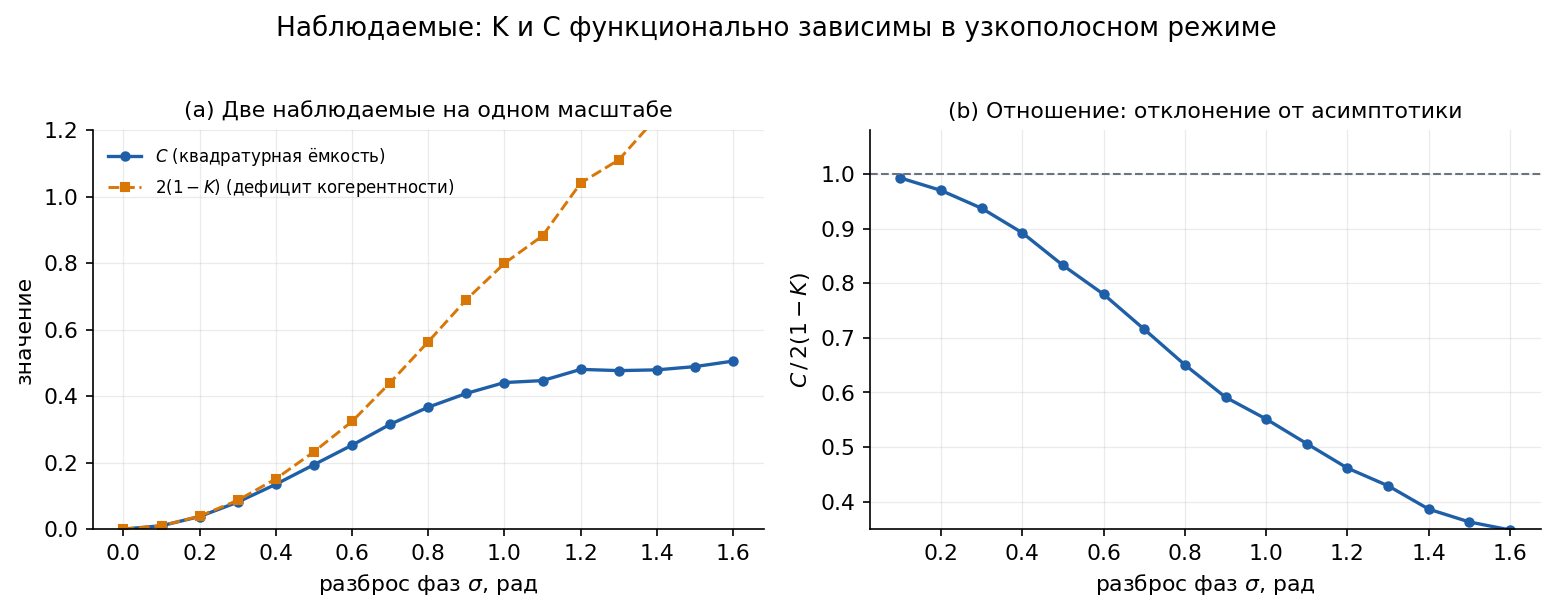

In [3]:
fig, m1 = ex.exp_observables()
print(f"Максимальное отклонение |C / 2(1-K) - 1| при sigma <= 0.2: {m1['ratio_small_sigma']:.3f}")
print(f"Отношение C / 2(1-K) при sigma = 1.0:                    {m1['ratio_at_sigma_1']:.3f}")
print(f"Ошибка U(1)-инвариантности C:                             {m1['invariance_error']:.2e}")
print("Эффективные размерности:")
for name, value in m1["effective_dimensions"].items():
    print(f"  {name:14s} {value:.3f}")


**Рис. 1.** Слева: $C$ и $2(1-K)$ как функции разброса фаз $\sigma$; кривые совпадают при $\sigma\lesssim0.4$ и расходятся при больших $\sigma$, когда разложение Предложения 3 перестаёт работать. Справа: отношение $C/2(1-K)$; при $\sigma\le0.2$ отклонение от единицы не превышает 3% (с учётом конечного $N$), при $\sigma=1$ отношение падает примерно до 0.55.

**Что это меняет.** В v7.2 $K$ и $C$ рассматривались как независимые координаты «фазового пространства». Численный эксперимент и Предложение 3 показывают, что в узкополосном режиме это одна и та же информация, записанная двумя способами. Независимость появляется только при широком распределении фаз или при неравных амплитудах — и тогда её нужно измерять, а не постулировать.


### 1.3. Энтропия: оценка и смещение

Энтропия $S_R$ — не «энтропия выбора» в метафизическом смысле, а обычная энтропия Шеннона распределения $p_i$. При оценке по конечной выборке она смещена вниз: если $m$ категорий наблюдаются с положительными вероятностями, то

$$
\mathbb{E}[\hat S_R]-S_R\approx-\frac{m-1}{2N}.
$$

Поправка Миллера—Мадоу

$$
\hat S_R^{\mathrm{MM}}=\hat S_R+\frac{\hat m-1}{2N},
\qquad \hat m=\#\{i:\hat p_i>0\},
$$

уменьшает смещение до $O(N^{-2})$ в стандартном режиме (фиксированное $m$, все категории наблюдаются с вероятностью, стремящейся к единице).

Это важно для программы измерений: без поправки любые сравнения энтропий при разных $N$ систематически смещены, а «рост энтропии» может оказаться артефактом объёма выборки.


Истинная энтропия: 1.8381 нат
Смещение при N=200: выборочное -0.0166 нат, с поправкой +0.0008 нат


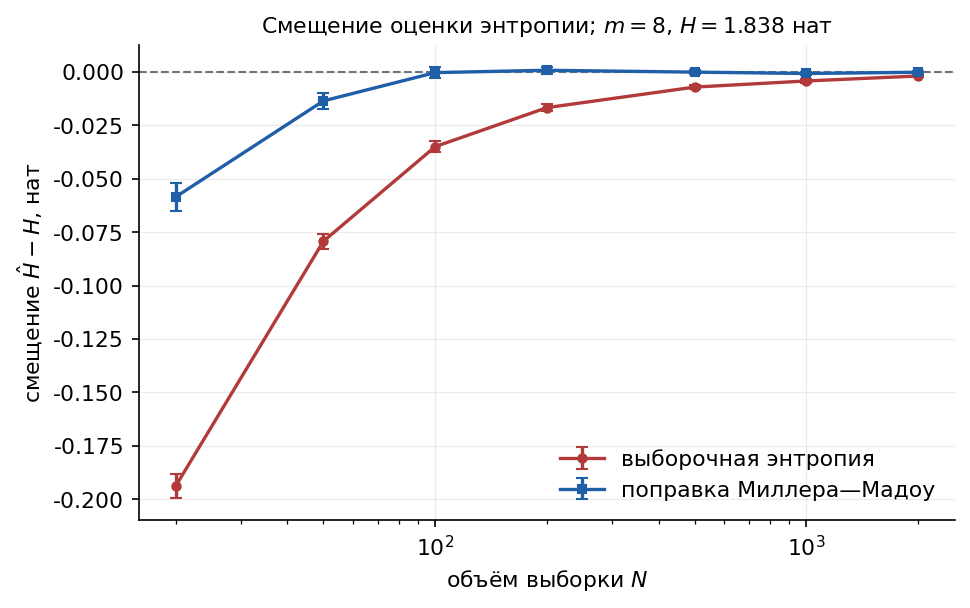

In [4]:
fig, m2 = ex.exp_entropy()
print(f"Истинная энтропия: {m2['H_true']:.4f} нат")
print(f"Смещение при N=200: выборочное {m2['bias_at_200_plugin']:+.4f} нат, "
      f"с поправкой {m2['bias_at_200_mm']:+.4f} нат")


**Рис. 2.** Смещение выборочной энтропии (красные точки) и оценки с поправкой Миллера—Мадоу (синие квадраты) как функции объёма выборки; показаны 95%-е интервалы. При $N=200$ выборочная оценка занижена примерно на 0.017 нат, поправка уменьшает смещение до $\sim0.001$ нат.

**Следствие для v7.2.** Утверждение «$S_R\to\max$» нельзя проверять по сырым выборочным энтропиям: максимум при конечном $N$ недостижим, а межвыборочные сравнения смещены. Все дальнейшие утверждения об энтропии должны формулироваться для оценки с поправкой и с доверительным интервалом.


## 2. Динамика $(E,C)$: что именно утверждает модель

### 2.1. Модель

Рассматривается редуцированная система из v7.2 (раздел 5):

$$
\frac{dE}{da}=-AE+BC,
\qquad
\frac{dC}{da}=-\beta C+\gamma(C)E,
\qquad
\gamma(C)=\frac{\gamma_0}{1+(C/C_0)^2},
\tag{2.1}
$$

где $A,B,\beta,\gamma_0,C_0>0$, а $E,C\ge0$ — нормированные «ошибка» и «ёмкость». Параметр $a$ — вещественная часть размерности, то есть просто параметр вдоль траектории; время в систему не входит.

**Обозначения.** В §1 $C(X)$ — функционал квадратурной ёмкости; в (2.1) $C$ — скалярная динамическая переменная, представляющая ёмкость. Это редукция, а не тождество: мы работаем с $C$ как с независимой переменной модели, а не как с функционалом состояния.

В v7.2 утверждалось, что у (2.1) есть предельный цикл. Ниже показано, что это не так — и не может быть при любых допустимых параметрах.


### 2.2. Теорема 1: периодических орбит нет

**Теорема 1 (Дюлак).** Пусть $A,B,\beta,\gamma_0,C_0>0$ и $\gamma'(C)\le0$ при $C\ge0$. Тогда система (2.1) не имеет замкнутых орбит в замкнутом первом квадранте $E\ge0$, $C\ge0$.

*Доказательство.* Возьмём функцию Дюлака $g(E,C)\equiv1$. Дивергенция поля

$$
\nabla\cdot(gF)=\frac{\partial}{\partial E}(-AE+BC)+\frac{\partial}{\partial C}\left(-\beta C+\gamma(C)E\right)
=-A-\beta+E\gamma'(C)\le-(A+\beta)<0.
$$

Если бы существовала замкнутая орбита, ограничивающая область $\Omega$, то по формуле Гаусса—Остроградского

$$
0=\oint_{\partial\Omega}F\cdot n\,ds=\int_\Omega\nabla\cdot F\,dA<0,
$$

противоречие. $\square$

**Ограниченность и $\omega$-предел.** В каноническом режиме траектории остаются в компактной области: при больших $E$ величина $\dot E$ отрицательна, а область, где обе производные положительны, ограничена кубической нелинейностью $\gamma(C)\sim C^{-2}$. Численная проверка для канонических параметров это подтверждает. Для произвольных допустимых параметров ограниченность — дополнительное условие, которое нужно проверять отдельно; без него теорема Пуанкаре—Бендиксона неприменима. При выполнении ограниченности $\omega$-предельное множество состоит из равновесий или замкнутых орбит; замкнутых орбит нет по теореме 1, значит, предельное множество — равновесие.


### 2.3. Теорема 2: равновесие — всегда устойчивый узел

**Теорема 2.** Пусть $u=\gamma_0B/(A\beta)-1>0$. Тогда у (2.1) существует единственное внутреннее равновесие

$$
C^*=C_0\sqrt{u},
\qquad
E^*=\frac{B}{A}C^*,
$$

и это равновесие является устойчивым узлом: собственные значения якобиана вещественны и отрицательны.

*Доказательство.* Равенство нулю правых частей даёт $C=(A/B)E$ и $\beta C=\gamma(C)E$. Подстановка первого во второе: $\gamma(C^*) = A\beta/B$, откуда $u=(\gamma_0B/(A\beta))-1=(C^*/C_0)^2$ и формулы для $C^*,E^*$ следуют.

Якобиан в равновесии:

$$
J=\begin{pmatrix}-A & B\\ \gamma(C^*) & -\beta+E^*\gamma'(C^*)\end{pmatrix}.
$$

Обозначим $x=-E^*\gamma'(C^*)>0$ (так как $\gamma'<0$). Тогда

$$
\operatorname{tr}J=-(A+\beta)-x<0,
\qquad
\det J= A x>0,
$$

$$
\Delta=(\operatorname{tr}J)^2-4\det J=(A-x)^2+2\beta(A+x)+\beta^2>0.
$$

Последнее выражение положительно при всех $A,\beta,x>0$. Следовательно, оба собственных значения вещественны; их сумма отрицательна, произведение положительно, значит, оба отрицательны. $\square$

**Явная формула.** Из $u=(C^*/C_0)^2$ и $\gamma(C^*)=A\beta/B$ получаем

$$
x=-E^*\gamma'(C^*)=\frac{2\beta u}{1+u}\in(0,2\beta).
$$

Поэтому $\operatorname{tr}J<-(A+\beta)$, а $\Delta=(A-x)^2+2\beta(A+x)+\beta^2>0$ при всех $A,\beta,x>0$; оценка не зависит от конкретного значения $u$.

**Следствие 1.** Предельного цикла нет; более того, нет и затухающих колебаний: собственные значения вещественны, мнимая часть равна нулю. Система релаксирует к узлу без колебаний.

**Следствие 2.** Шумовая «квазициклическая» интерпретация тоже невозможна в линейном приближении: у устойчивого узла с вещественными собственными значениями спектральная плотность мощности не имеет внутреннего максимума. Любое наблюдаемое колебание в такой модели требует внешнего периодического воздействия или структурного изменения уравнений.

**Проекция.** В v7.2 $\chi$ не входит в правые части (2.1). Поэтому любой детерминированный цикл в расширенном пространстве $(E,C,\chi)$ проектировался бы в замкнутую орбиту (2.1), которой нет по теореме 1. Шумовая динамика $\chi$ может давать стохастические колебания, но это не предельный цикл.


Равновесие: E* = 1.224745, C* = 1.224745
Собственные значения: [-2.76619 -0.43381]
tr J = -3.2000;  det J = 1.2000;  Delta = 5.4400
Численная скорость сходимости: 0.4443
max div на сетке [0,4]^2: -2.0000
min Delta на сетке параметров: 4.3265
rho(J_map): min = 0.3457, max = 0.9957
Полунеявная схема устойчива на исследованном диапазоне: True


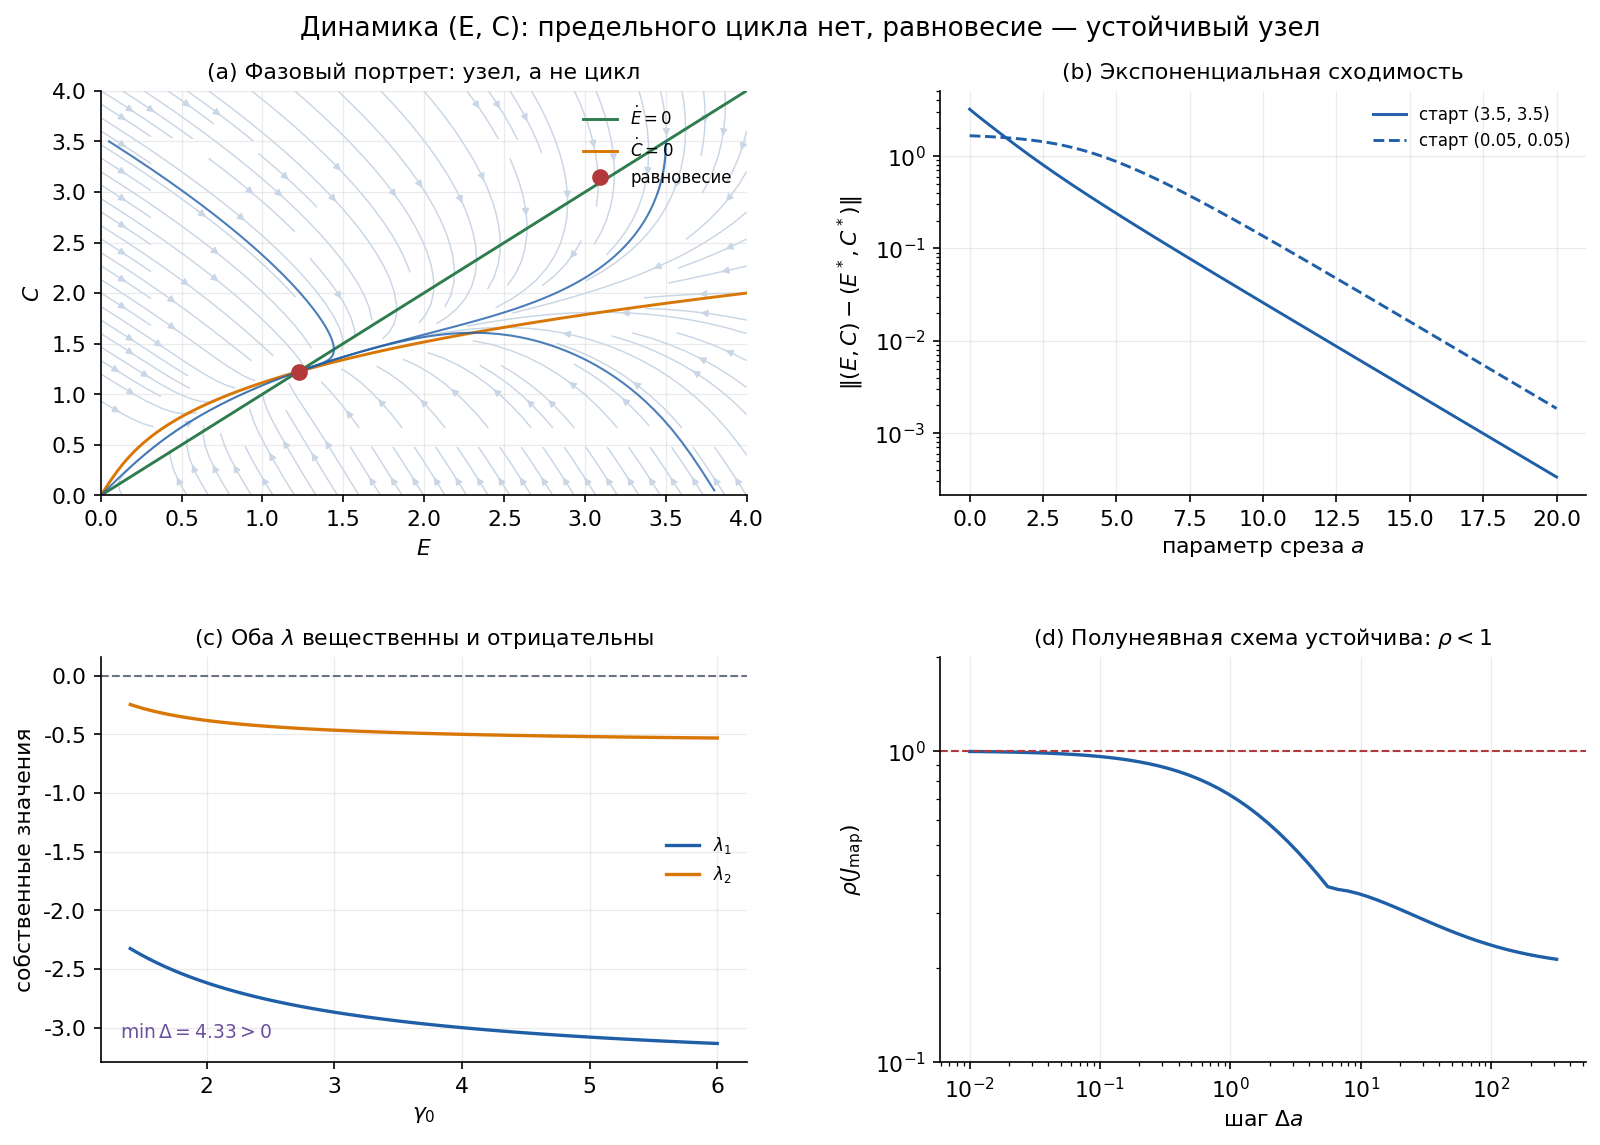

In [5]:
flow = Flow()
fig, m3 = ex.exp_dynamics(flow)

print(f"Равновесие: E* = {m3['fixed_point'][0]:.6f}, C* = {m3['fixed_point'][1]:.6f}")
print(f"Собственные значения: {np.round(m3['eigenvalues'], 6)}")
print(f"tr J = {m3['trace']:.4f};  det J = {m3['det']:.4f};  Delta = {m3['disc']:.4f}")
print(f"Численная скорость сходимости: {m3['convergence_rate']:.4f}")
print(f"max div на сетке [0,4]^2: {m3['max_divergence_on_grid']:.4f}")
print(f"min Delta на сетке параметров: {m3['min_discriminant_on_grid']:.4f}")
print(f"rho(J_map): min = {m3['min_map_radius']:.4f}, max = {m3['max_map_radius']:.4f}")
print(f"Полунеявная схема устойчива на исследованном диапазоне: {m3['map_stable_for_all_tested_deltas']}")


**Рис. 3.** (a) Фазовый портрет: все траектории сходятся к узлу $(1.2247,1.2247)$; цветные линии — нуль-изоклины. (b) Экспоненциальная сходимость: наклон прямой на полулогарифмическом графике соответствует скорости $\approx0.44$, что близко к $|\lambda_{\max}|=0.434$. (c) Собственные значения как функции $\gamma_0$: оба вещественны и отрицательны, дискриминант всюду положителен ($\min\Delta=4.33$). (d) Спектральный радиус якобиана полунеявной схемы $\rho<1$ во всём исследованном диапазоне шагов $10^{-2}\le\Delta a\le10^{2.5}$.

**Интерпретация.** Утверждение v7.2 о предельном цикле не подтверждается: его нет ни в непрерывной системе, ни в её стандартной дискретизации. Более сильный результат: равновесие всегда является узлом, поэтому в модели нет даже колебательной переходной динамики. Это не «отрицательный результат о частном случае», а структурное свойство класса (2.1) при $\gamma'\le0$.


### 2.4. Дискретизация не создаёт цикл

В v7.2 использовалась полунеявная схема

$$
E_{n+1}=\frac{E_n+\Delta a\,B C_n}{1+A\Delta a},
\qquad
C_{n+1}=\frac{C_n+\Delta a\,\gamma(C_n)E_{n+1}}{1+\beta_1\Delta a}.
\tag{2.2}
$$

Неподвижная точка (2.2) совпадает с равновесием (2.1). Спектральный радиус якобиана отображения в равновесии $\rho(\Delta a)$ определяет локальную устойчивость. Численно $\rho<1$ на всём диапазоне $10^{-2}\le\Delta a\le10^{2.5}$, причём $\rho\to1$ при $\Delta a\to0$ (что ожидаемо: схема первого порядка) и $\rho$ убывает с ростом шага. Значит, заявленная в v7.2 «цикличность» не объясняется и артефактом дискретизации при канонических параметрах.

**Оговорка.** При экстремальных, физически недопустимых параметрах схема может терять устойчивость: например, при $A=0.118$, $B=7.316$, $\beta=5.86$, $\gamma_0=6.311$, $C_0=0.2$, $\Delta a=1.288$ итерации (2.2) выходят на период-2 с $E\approx270$–$300$, что соответствует «ошибке» больше единицы и выходит за область нормированных величин. Это не реабилитирует цикл, но показывает, почему при воспроизведении необходимо указывать $\rho$ и область параметров.


In [6]:
extreme = Flow(A=0.118, B=7.316, beta=5.86, gamma0=6.311, C0=0.2)
trajectory = semi_implicit_trajectory(extreme, 1.288, n_steps=20000)
last = trajectory[-1000:]
print(f"rho(J_map) = {extreme.map_spectral_radius(1.288):.3f}  (> 1: локальная неустойчивость)")
print(f"E в последних 1000 итерациях: min = {last[:, 0].min():.2f}, max = {last[:, 0].max():.2f}")
print("Последние 4 значения E:", np.round(trajectory[-4:, 0], 2))
print("Последние 4 значения C:", np.round(trajectory[-4:, 1], 2))


rho(J_map) = 1.548  (> 1: локальная неустойчивость)
E в последних 1000 итерациях: min = 269.53, max = 299.95
Последние 4 значения E: [299.95 269.53 299.95 269.53]
Последние 4 значения C: [1.12 8.07 1.12 8.07]


### 2.5. Что нужно, чтобы предельный цикл всё-таки существовал

Для двумерной автономной системы стандартный механизм рождения цикла — бифуркация Хопфа; для неё необходимо, чтобы в некоторой точке выполнялось

$$
\operatorname{tr}J=0,
\qquad
\det J>0.
$$

В классе (2.1) при $\gamma'\le0$ выполнено $\operatorname{tr}J<-(A+\beta)<0$ в равновесии, поэтому бифуркация Хопфа невозможна. Нужно структурное изменение. Минимальные варианты:

1. **Антагонистическая связь.** Сделать одно из слагаемых отрицательным (ёмкость подавляет ошибку, ошибка стимулирует ёмкость). Тогда возможны комплексные собственные значения и устойчивый фокус; для цикла требуется потеря устойчивости, то есть положительная обратная связь или запаздывание.
2. **Запаздывание.** Модель
$$
\dot E=-AE-BC(a-\tau)+S,
\qquad
\dot C=-\beta C+\gamma E
\tag{2.3}
$$
имеет характеристическое уравнение
$$
(\lambda+A)(\lambda+\beta)+B\gamma e^{-\lambda\tau}=0.
$$
Подстановка $\lambda=i\omega$ даёт условие Хопфа $B\gamma>A\beta$ и частоту
$$
\omega^2=\frac{-(A^2+\beta^2)+\sqrt{(A^2+\beta^2)^2-4(A^2\beta^2-B^2\gamma^2)}}{2},
$$
а критическое запаздывание $\tau_c$ находится из фазового условия
$$
\cos(\omega\tau)=\frac{\omega^2-A\beta}{B\gamma},
\qquad
\sin(\omega\tau)=\frac{\omega(A+\beta)}{B\gamma}>0.
$$
Линейная модель (2.3) при $B\gamma>A\beta$ и $\tau>\tau_c$ даёт нарастающие колебания; для стабильного предельного цикла нужна нелинейность, ограничивающая амплитуду. Это уже отдельная гипотеза о механизме, а не следствие v7.2.
3. **Автокатализ.** Положительный диагональный вклад (например, слагаемое $\delta EC$ в уравнении для $E$ или $\delta C^2$ в уравнении для $C$) может сделать $\operatorname{tr}J$ положительным. Но тогда нужно отдельно проверить, что равновесие существует, что потеря устойчивости действительно происходит и что нелинейность ограничивает амплитуду; сам по себе положительный диагональный член ничего не гарантирует.

**Вывод.** Предельный цикл в v7.2 — не результат модели, а предполагаемая возможность. Чтобы превратить её в научное утверждение, нужно указать механизм (запаздывание, антагонизм, автокатализ), измерить его параметры и показать, что система действительно находится в соответствующей области. Без этого «предельный цикл» — необоснованная интерпретация.


## 3. От «Грани гармонии» к калиброванному решению

### 3.1. Задача обнаружения

Пусть есть $n$ наблюдений и $p$ признаков-кандидатов. Для каждого признака $j$ вычисляется выборочный выигрыш $R^2_{\mathrm{in},j}$ (например, прирост объяснённой дисперсии при добавлении признака). Нужно решить, какие признаки считать содержательными, а какие — шумом.

В v7.2 для этого использовался индекс

$$
\chi(X)=\frac{\mu(X)}{\nu(X)}\cdot\frac{1-\langle\cos\Delta\phi\rangle_{\text{окр}}}{1+|\Delta\alpha|/\lambda},
$$

а порог $\chi_{\text{crit}}$ объявлялся динамическим. У этого правила нет нулевого распределения: величина $\chi$ не имеет вероятностной модели, а порог не контролирует ни одну частотную ошибку. Поэтому «гениальный выброс» и «паразитическая мнимость» не являются статистически различимыми категориями — это ярлыки для одного и того же события: большого выборочного выигрыша.

### 3.2. Что можно измерить

Для выбранного множества $S$:

$$
\text{precision}=\frac{TP}{|S|},
\qquad
\text{recall}=\frac{TP}{k},
\qquad
\text{FDR}=\mathbb{E}\left[\frac{FP}{|S|}\right],
$$

где $k$ — число истинных признаков (в моделировании известно, в реальной задаче — нет). Дополнительно измеряется выигрыш **вне выборки** $R^2_{\mathrm{out}}$: он показывает, переносится ли найденный эффект на новые данные.

Три процедуры:

* **Наивный порог (top-$m$):** выбрать $m$ признаков с наибольшим $R^2_{\mathrm{in}}$. Число ошибок не контролируется.
* **Бенджамини—Хохберг (BH):** по $p$-значениям выбрать признаки, проходящие step-up процедуру на уровне $q$; контролирует FDR при независимости или положительной зависимости (PRDS).
* **Перестановочный максимум:** смоделировать распределение $\max_j R^2_{\mathrm{in}}$ при случайной перестановке меток и взять его квантиль уровня $1-\alpha$; контролирует FWER.

### 3.3. Эксперимент

Параметры: $n=100$, $p=200$, $k=2$ истинных признака с эффектом $0.45$, 1000 реализаций, бюджет наивного порога $m=10$, $q=0.1$, 500 перестановок.


Наивный top-10   precision=0.195  recall=0.975  FDR=0.805  R2_out=-0.022  AUC=0.994
BH, q = 0.1      precision=0.896  recall=0.754  FDR=0.097  R2_out=+0.111  AUC=0.994

Порог top-10: 0.035
95%-й квантиль нулевого максимума: 0.129
Проклятие победителя: средний R2_in = 0.188, средний R2_out = 0.129


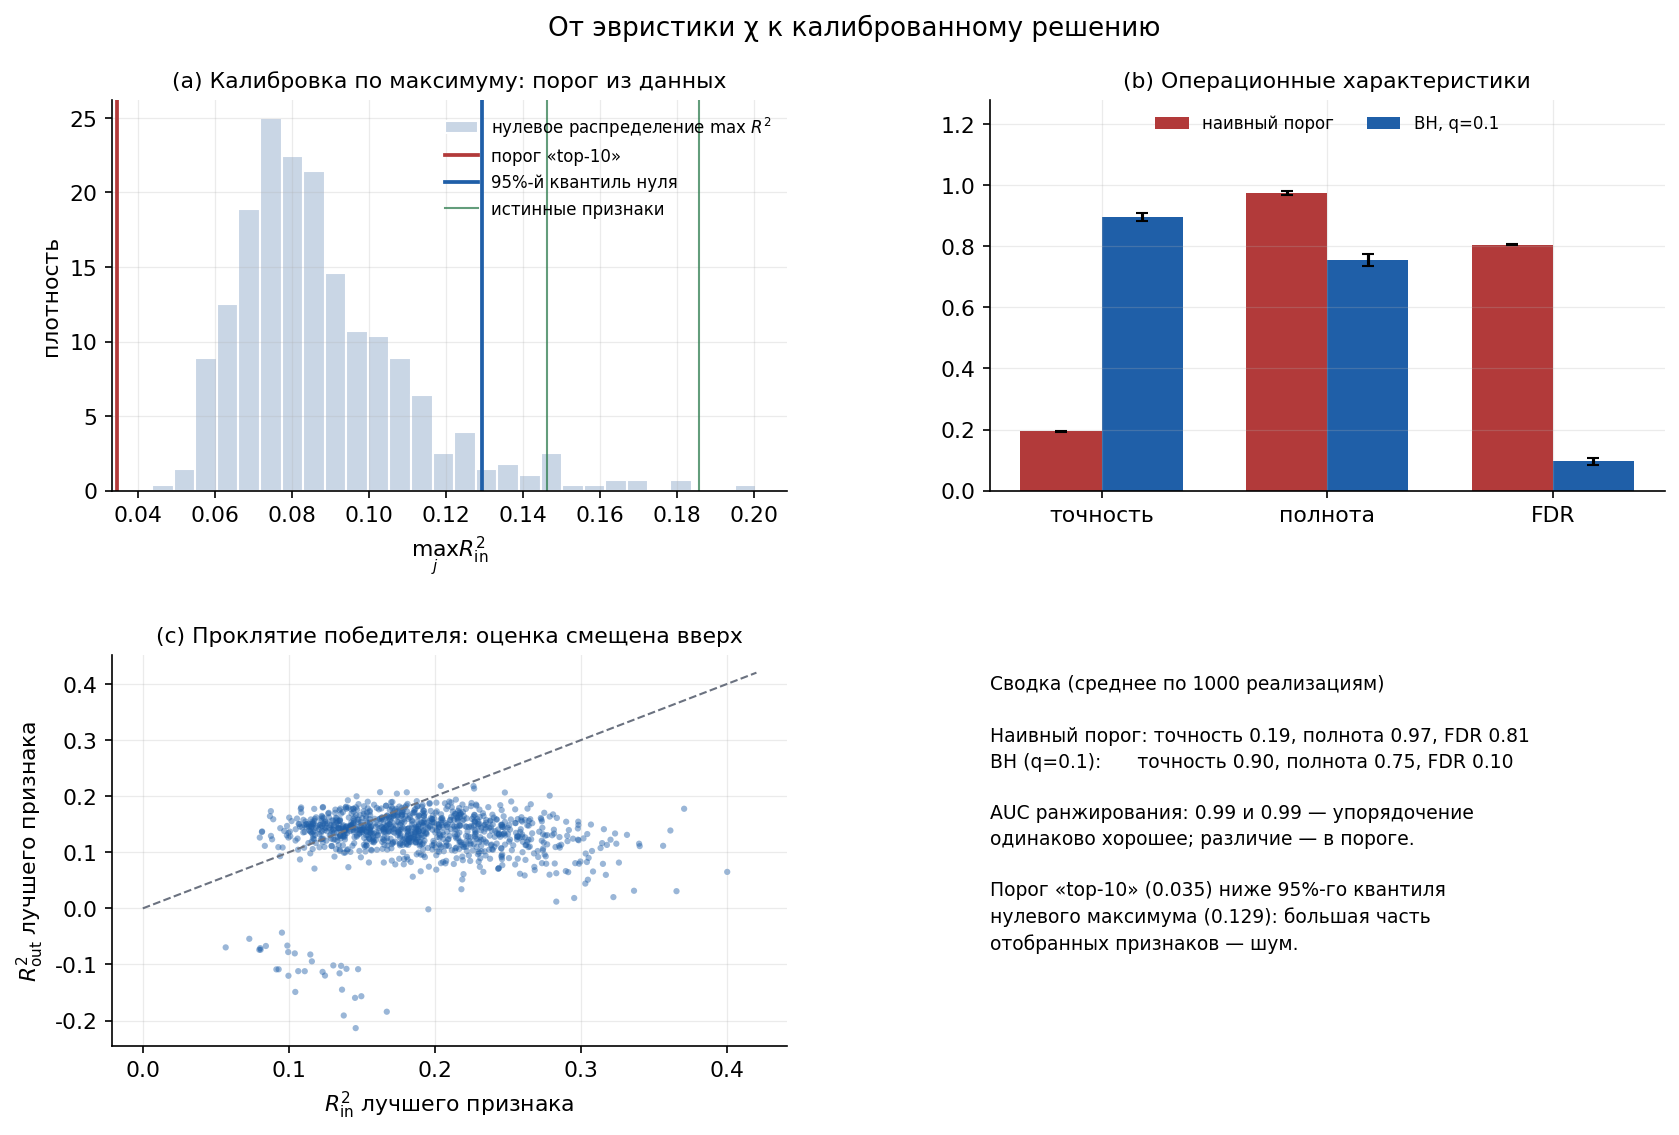

In [7]:
fig, m5 = ex.exp_detection(reps=1000, n_perm=500)

for key, label in (("raw_top", "Наивный top-10"), ("bh", "BH, q = 0.1")):
    mm = m5["metrics"][key]
    print(f"{label:16s} precision={mm['precision']:.3f}  recall={mm['recall']:.3f}  "
          f"FDR={mm['fdr']:.3f}  R2_out={mm['mean_out_of_sample_r2']:+.3f}  AUC={mm['auc']:.3f}")

print(f"\nПорог top-10: {m5['example']['raw_cut']:.3f}")
print(f"95%-й квантиль нулевого максимума: {m5['example']['null_q95']:.3f}")
print(f"Проклятие победителя: средний R2_in = {m5['winner']['in_sample'].mean():.3f}, "
      f"средний R2_out = {m5['winner']['out_of_sample'].mean():.3f}")


**Рис. 4.** (a) Нулевое распределение максимума $R^2_{\mathrm{in}}$ при перестановке меток (500 перестановок), 95%-й квантиль (синяя линия), наивный порог top-10 (красная линия) и значения истинных признаков (зелёные линии). Наивный порог лежит ниже нулевого квантиля: большая часть отобранных им признаков — шум. (b) Точность, полнота и FDR для наивного порога и BH; показаны 95%-е интервалы. (c) Выборочный выигрыш лучшего признака против его выигрыша вне выборки: точки преимущественно ниже диагонали — оценка смещена вверх.

**Результаты.** Наивный порог: precision $0.20$, recall $0.97$, FDR $0.81$, $R^2_{\mathrm{out}}=-0.02$. BH: precision $0.90$, recall $0.75$, FDR $0.10$, $R^2_{\mathrm{out}}=+0.11$. AUC ранжирования в обоих случаях $\approx0.99$: **упорядочение признаков по выборочному выигрышу само по себе хорошее; проблема — в пороге.** Именно поэтому замена «магического» $\chi_{\text{crit}}$ на калиброванный порог даёт выигрыш без изменения ранжирования.

**Следствие для Аксиомы 22.** «Гениальность» не является отдельной онтологической категорией, которую можно распознать по $\chi$. Это малый эффект, который (i) переживает калибровку, (ii) воспроизводится на новых данных и (iii) имеет сообщённый размер эффекта с доверительным интервалом. Наивный порог систематически путает шум с сигналом; калиброванный — контролирует долю ложных открытий, но не гарантирует истинность каждого отдельного открытия. Универсальной гарантии «сохранить гения при любом конечном $n$» не существует: это прямое следствие невозможности бесплатного обеда в статистике.

**Оговорка.** Эксперимент не вычисляет $\chi$ буквально: он моделирует ключевое свойство $\chi$-порога — отбор по выборочному выигрышу без нулевого распределения. Прямая проверка $\chi$ требует данных с известной истиной и оставлена на полевой этап (H3).


## 4. Срединный путь как задача управления

### 4.1. Функционал баланса

В редуцированной модели $(E,C)$ определим

$$
\mu(E,C)=\frac12\left[\frac{E}{1+E}+\frac{C}{1+C}\right],
\qquad
\nu(E,C)=\frac12\left[\frac{1}{1+E}+\frac{1}{1+C}\right].
$$

Тогда $\mu+\nu=1$ и

$$
\mu-\nu=\frac{EC-1}{(1+E)(1+C)}.
$$

Множество баланса $\{\mu=\nu\}$ — гипербола $EC=1$. Это двумерный вариант той же идеи, что и в Определении 1.4: коразмерности один, а не точка и не аттрактор.

### 4.2. Свободная динамика

Для (2.1) равновесие имеет $E^*C^*=(1.2247)^2=1.5$, то есть лежит вне множества баланса: $\mu-\nu\approx0.10$. Траектория из начальной точки $(0.05,0.05)$ пересекает $EC=1$ ровно один раз и уходит к равновесию. Баланс — **переходное событие**, а не состояние, к которому система стремится.

### 4.3. Управление

Если добавить в уравнение для $E$ управляющее слагаемое $u$, то

$$
\frac{d(EC)}{da}=C(-AE+BC+u)+E(-\beta C+\gamma(C)E).
$$

Выбор

$$
u=\frac{-k(EC-1)+(A+\beta)EC-BC^2-\gamma(C)E^2}{C}
$$

(при $C>0$) даёт $\frac{d(EC)}{da}=-k(EC-1)$, то есть $EC\to1$ экспоненциально. Это не «закон природы», а демонстрация: баланс достижим, если в системе есть соответствующая обратная связь. Вопрос о том, есть ли она в конкретной системе, — эмпирический.


Равновесие: E*C* = 1.5000, разрыв баланса = 0.1010
Пересечений EC=1 без управления: 1
Пересечений EC=1 с управлением:  0
Конечное EC с управлением:        1.000000
Конечный |EC-1| с управлением:    5.33e-15


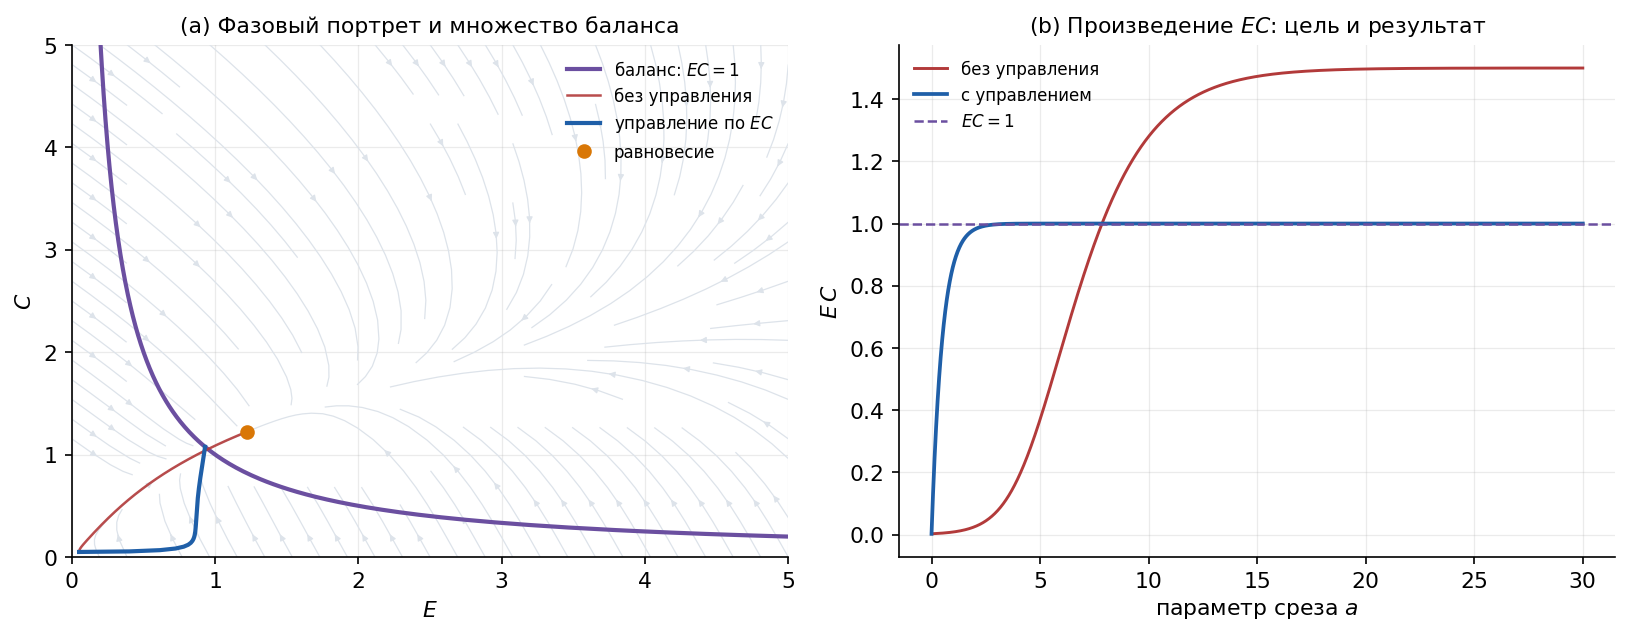

In [8]:
flow = Flow()
fig, m4 = ex.exp_balance(flow)
print(f"Равновесие: E*C* = {m4['equilibrium_product']:.4f}, разрыв баланса = {m4['equilibrium_gap']:.4f}")
print(f"Пересечений EC=1 без управления: {m4['uncontrolled_crossings']}")
print(f"Пересечений EC=1 с управлением:  {m4['controlled_crossings']}")
print(f"Конечное EC с управлением:        {m4['controlled_final_product']:.6f}")
print(f"Конечный |EC-1| с управлением:    {m4['controlled_final_abs_gap']:.2e}")


**Рис. 5.** (a) Фазовый портрет, гипербола баланса $EC=1$, свободная траектория (красная) и траектория с обратной связью (синяя); равновесие свободной системы лежит вне гиперболы. (b) Произведение $EC$ вдоль траекторий: свободная система проходит через 1 и уходит к 1.5; управляемая выходит на 1 и удерживается.

**Следствие для Аксиомы 21.** Утверждение «Срединный путь — аттрактор» в редуцированной модели неверно: баланс пересекается трансверсально и не удерживается. Корректная формулировка: **баланс — это целевое множество, которое может стабилизироваться управлением.** Проверяемая гипотеза состоит в том, что конкретная система обладает обратной связью, удерживающей $\mu\approx\nu$; её нужно формулировать как задачу о времени пребывания в окрестности $\{\mu=\nu\}$ и о реакции на возмущения, а не как аксиому.


## 5. Гипотезы и критерии фальсификации

Ниже — минимальный набор утверждений, которые можно проверить и, в принципе, опровергнуть. Для каждой гипотезы указаны предсказание, нулевая модель и текущий статус.

| ID | Гипотеза | Предсказание | Нулевая модель / тест | Статус |
|---|---|---|---|---|
| **H1** | В классе (2.1) с $A,B,\beta>0$ и $\gamma'\le0$ нет устойчивых колебаний | Спектральная плотность мощности не имеет внутреннего максимума (в линейном приближении); квазициклический пик отсутствует | Спектральный тест: AR(2) с вещественными корнями против комплексных; теоремы 1—2 | Подтверждена аналитически и численно |
| **H2** | $K$ и $C$ избыточны в узкополосном режиме | $C/2(1-K)\to1$ при $\sigma\to0$; отклонение $<5\%$ при $\sigma<0.3$ | Монте-Карло по $\sigma$; проверка Предложения 3 | Подтверждена |
| **H3** | Наивный $\chi$-порог не контролирует FDR | $\mathrm{FDR}_{\text{naive}}>0.5$ при $\mathrm{FDR}_{\text{BH}}\le0.15$ | Регрессионный прокси-эксперимент (разд. 3) | Подтверждена на прокси; нужна проверка на полевых данных |
| **H4** | Множество баланса не является аттрактором свободной системы | Конечное число пересечений, отсутствие сходимости $\mu-\nu\to0$ | Прямое интегрирование (2.1); счёт пересечений | Подтверждена в редуцированной модели |
| **H5** | Когерентностная регуляризация повышает устойчивость комплекснозначного классификатора к фазовому шуму | Точность при фазовом шуме выше, чем у базовой модели, при том же числе параметров | Пре-регистрированный эксперимент: фаза-кодированная задача, сравнение с real-valued baseline, 20 сидов | Планируется |

**Чего эти гипотезы не утверждают.** Они не утверждают, что «метапространство» существует как физическая реальность, что размерность может быть комплексной в смысле метрического пространства, или что когерентность — универсальная валюта природы. Они утверждают только то, что перечисленные величины измеримы, а перечисленные связи — проверяемы.

**Правило остановки.** Эксперимент останавливается не при «стабилизации $\langle\chi\rangle$ на предельном цикле», а при достижении заранее заданной точности оценки эффекта и контроле FDR. Это правило воспроизводимо и не зависит от интерпретации.


## 6. Программа работ

**Ближайшие 6 месяцев — теория.**

* Классифицировать двумерные и трёхмерные расширения (2.1) по знаковой структуре якобиана; исследовать условия глобальной устойчивости для более широкого класса, чем $\gamma'\le0$.
* Вывести условия Хопфа для моделей с запаздыванием и антагонизмом; отделить «механизм» от «подгонки».
* Оформить отрицательный результат (теоремы 1—2) как самостоятельную публикацию: отрицательные результаты полезны, если они структурны.

**6–12 месяцев — измерения.**

* Реализовать оценки $K$, $S_R$, $C$, $D_{\mathrm{eff}}$ с доверительными интервалами и поправками на смещение.
* Пре-регистрировать протокол проверки H1—H4 на реальных данных (временные ряды фаз, комплекснозначные нейросети, синхронизация осцилляторов).
* Опубликовать код и данные; фиксировать версии и сиды.

**12–18 месяцев — приложения.**

* Комплекснозначный перцептрон с фазовым кодированием: сравнить с real-valued baseline при фазовом шуме (H5).
* Проверить, предсказывает ли когерентность весов обобщение; если нет — опубликовать отрицательный результат.
* Оценить, помогает ли балансовая регуляризация; если нет — закрыть направление.

**Критерий успеха проекта** — не «достижение гармонии», а набор воспроизводимых, опровержимых утверждений с контролем ошибок. **Критерий провала** — возврат к формулировкам, которые нельзя проверить.


## 7. Что удалено и почему

Полный аудит 22 аксиом, 7 «теорем», а также разделов об алгебре, топологии, исчислении и приложениях приведён в `docs/audit.md`. Здесь — сводка по категориям.

| Элемент v7.2 | Статус в v8 | Причина |
|---|---|---|
| «Квант мерности» $\lambda=0.020203236\ldots$, шесть сфер (7,6,5,4,3,2 форм) | Удалено | Нет вывода, единиц, погрешности и независимого измерения; числа не следуют из модели |
| $\alpha_{\text{life}}=\pi$ | Удалено | $\pi$ не является размерностью; нет механизма, объясняющего, почему жизнь требует именно этой величины |
| Деление на ноль $X\oslash\mathbf{0}_{\mathfrak{M}}$ | Удалено | Операция не определена; «повышение мерности» не следует из математики. Реальный аналог — перенормировка и аномальная размерность $d_{\mathrm{eff}}=d+\gamma$, которая вычисляется |
| «Мнимый нуль» $\mathbf{0}_{\text{imag}}$, $\mathbf{1}_{\text{imag}}^2=-\mathbf{1}$ | Удалено | $\mathbb{C}$ стандартна, $i^2=-1$ не требует новой аксиомы; «мнимый нуль» не определён, и его совместимость нельзя проверить без задания операции. Для нильпотентных величин есть алгебра Грассмана ($\theta^2=0$, $\theta_i\theta_j=-\theta_j\theta_i$), но она не следует из «мнимости» |
| Суперсимметрия с суперпартнёрами | Удалено как физическое утверждение | Нет предсказаний и частиц; остаётся только $\mathbb{Z}_2$-градуировка как математическая аналогия |
| Автомнимость (для любого $X$ есть $\varphi_X$) | Удалено | Тавтологично: $\varphi_X=\mathrm{id}$ удовлетворяет условию; утверждение не содержит информации |
| «Теорема Пуанкаре—Перельмана», «теорема Ферма для $\mathfrak{M}$» | Удалено | Не сформулированы как математические утверждения: нет пространства, операции, кванторов и доказательства |
| Алгебра $\oplus,\otimes,\circledast,\oslash$; группа $\mathcal{G}_{\mathfrak{M}}$ | Удалено/не используется | Операции не определены на общем носителе; формула обратного элемента не проверена как обратная. Для v8 достаточно стандартных операций над $\mathbb{C}^N$ |
| Топология: компоненты $\mathcal{C}_0,\mathcal{C}_{\mathrm{IV}},\mathcal{C}_{\mathrm{III}},\mathcal{C}_{\mathrm{II}}$; $\pi_1=\mathbb{Z}\oplus\mathbb{Z}_2$ | Удалено | Нет определений, отображений и доказательств; утверждение о фундаментальной группе не проверяемо |
| Фрактальная производная комплексного порядка; «дифференциал повышает размерность» | Удалено | Формула Грюнвальда—Летникова определена для вещественного порядка; комплексный порядок требует отдельного определения. Дифференцирование не повышает размерность |
| Приложения: термоядерный синтез, теория струн, «тёмная материя» | Удалено | Нет расчётов, единиц и проверяемых предсказаний; утверждения не являются научными гипотезами в текущей форме |
| Анти-второе начало | Понижено | Как универсальное утверждение ложно (декогеренция увеличивает $S_R$ и уменьшает $K$); заменено балансом энтропии открытой системы |
| Возвращение Пуанкаре | Переформулировано | Применимо к консервативным системам с конечной мерой; модель (2.1) диссипативна, возвращение не гарантировано |
| Философские цитаты | Удалено из научного текста | Не являются проверяемыми утверждениями; могут остаться в популярном изложении |

**Что сохранено.** Определения $K$, $S_R$, $C$; идея комплексного параметра $\alpha=a+ib$ (как эффективная размерность плюс параметр аналитического продолжения); иерархия функциональных пространств как математическая конструкция; функционалы баланса; эвристика $\chi$ как исходная точка (но не как решающее правило).


## 8. Воспроизводимость

**Среда.** Python $\ge3.11$, `numpy`, `scipy`, `matplotlib`. Полный список — в `requirements.txt`; установка пакета — `pip install -e .`.

**Команды.**

```bash
python experiments/run_all.py     # все рисунки и results/metrics.json
python tests/test_core.py         # 16 тестов, без pytest
python tools/build_notebook.py    # пересобрать и исполнить этот ноутбук
```

**Данные и сиды.** Все эксперименты детерминированы: E1 — `seed=0`, E2 — `seed=0`, E3/E4 — без случайности, E5 — `seed=1`. Числа в тексте соответствуют `results/metrics.json`; при изменении параметров они пересчитываются.

**Время.** Полный прогон на ноутбуке занимает несколько секунд; детекционный эксперимент (1000 реализаций, 500 перестановок) — около 4 с.

**Структура.**

```
metaspace/            # библиотека: наблюдаемые, динамика, баланс, статистика
experiments/run_all.py
tests/test_core.py
tools/build_notebook.py
notebooks/metaspace_v8.ipynb
results/figures/      # рисунки
results/metrics.json  # метрики
docs/audit.md         # аудит аксиом
```

**Ограничение.** Все численные результаты получены на синтетических данных; они проверяют математические утверждения и статистические процедуры, но не являются эмпирическим подтверждением «метапространства».


## 9. Литература

1. Kuramoto, Y. (1984). *Chemical Oscillations, Waves, and Turbulence*. Springer.
2. Strogatz, S. H. (2000). From Kuramoto to Crawford: exploring the onset of synchronization in populations of coupled oscillators. *Physica D*, 143(1–4), 1–20.
3. Shannon, C. E. (1948). A mathematical theory of communication. *Bell System Technical Journal*, 27(3), 379–423.
4. Miller, G. A. (1955). Note on the bias of information estimates. In *Information Theory in Psychology* (pp. 95–100). Free Press.
5. Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B*, 57(1), 289–300.
6. Burnham, K. P., & Anderson, D. R. (2002). *Model Selection and Multimodel Inference* (2nd ed.). Springer.
7. Perko, L. (2001). *Differential Equations and Dynamical Systems* (3rd ed.). Springer.
8. Hale, J. K., & Lunel, S. M. V. (1993). *Introduction to Functional Differential Equations*. Springer.
9. Guckenheimer, J., & Holmes, P. (1983). *Nonlinear Oscillations, Dynamical Systems, and Bifurcations of Vector Fields*. Springer.
10. Prigogine, I. (1967). *Thermodynamics of Irreversible Processes* (3rd ed.). Wiley.
11. Cover, T. M., & Thomas, J. A. (2006). *Elements of Information Theory* (2nd ed.). Wiley.
12. MacKay, D. J. C. (2003). *Information Theory, Inference, and Learning Algorithms*. Cambridge University Press.
13. Ioannidis, J. P. A. (2005). Why most published research findings are false. *PLoS Medicine*, 2(8), e124.


## Приложение. Аудит аксиом

Полная таблица «аксиома → вердикт → обоснование» — в [`docs/audit.md`](../docs/audit.md). Кратко: из 22 аксиом v7.2 сохранены как определения или конструкции 5, переформулированы и ограничены 4, понижены до гипотез или задач 4, удалены как неопределённые или нефальсифицируемые 9. Из 7 «теорем» ни одна не сохранила статус теоремы в исходной формулировке; две заменены корректными утверждениями (теоремы 1—2 настоящего текста), остальные удалены.

---

*Конец документа. Версия 8.0.*


In [9]:
print("Сводка ключевых чисел")
print("-" * 62)
print(f"{'равновесие E*':28s} {m3['fixed_point'][0]:>12.6f}")
print(f"{'равновесие C*':28s} {m3['fixed_point'][1]:>12.6f}")
print(f"{'lambda_1':28s} {m3['eigenvalues'][0]:>12.6f}")
print(f"{'lambda_2':28s} {m3['eigenvalues'][1]:>12.6f}")
print(f"{'дискриминант':28s} {m3['disc']:>12.4f}")
print(f"{'max div на [0,4]^2':28s} {m3['max_divergence_on_grid']:>12.4f}")
print(f"{'min Delta по gamma_0':28s} {m3['min_discriminant_on_grid']:>12.4f}")
print(f"{'FDR наивного порога':28s} {m5['metrics']['raw_top']['fdr']:>12.3f}")
print(f"{'FDR BH':28s} {m5['metrics']['bh']['fdr']:>12.3f}")
print(f"{'precision BH':28s} {m5['metrics']['bh']['precision']:>12.3f}")
print(f"{'recall BH':28s} {m5['metrics']['bh']['recall']:>12.3f}")
print(f"{'EC в равновесии':28s} {m4['equilibrium_product']:>12.4f}")
print(f"{'|EC-1| с управлением':28s} {m4['controlled_final_abs_gap']:>12.1e}")


Сводка ключевых чисел
--------------------------------------------------------------
равновесие E*                    1.224745
равновесие C*                    1.224745
lambda_1                        -2.766190
lambda_2                        -0.433810
дискриминант                       5.4400
max div на [0,4]^2                -2.0000
min Delta по gamma_0               4.3265
FDR наивного порога                 0.805
FDR BH                              0.097
precision BH                        0.896
recall BH                           0.754
EC в равновесии                    1.5000
|EC-1| с управлением              5.3e-15
